# Лабораторна робота №4: класифікація ірисів

Реалізація розділу **“A First Application: Classifying Iris Species”** із книги *Introduction to Machine Learning with Python* (сторінки PDF 27–38). Мета — навчити модель визначати вид квітки за довжиною та шириною чашолистка і пелюстки (у сантиметрах). Це задача класифікації з учителем: для навчальних зразків правильні види відомі.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier


## 1. Знайомство з даними

Набір Iris уже входить до `scikit-learn`: 150 квіток, чотири ознаки та три види — setosa, versicolor, virginica.


In [2]:
iris_dataset = load_iris()
print("Ключі набору:", list(iris_dataset.keys()))
print("Назви класів:", iris_dataset.target_names)
print("Назви ознак:", iris_dataset.feature_names)
print("Розмір X:", iris_dataset.data.shape)
print("Розмір y:", iris_dataset.target.shape)
print("Перші 5 зразків:\n", iris_dataset.data[:5])
print("Коди класів і кількість зразків:", dict(zip(*np.unique(iris_dataset.target, return_counts=True))))


Ключі набору: ['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module']
Назви класів: ['setosa' 'versicolor' 'virginica']
Назви ознак: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Розмір X: (150, 4)
Розмір y: (150,)
Перші 5 зразків:
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]
Коди класів і кількість зразків: {np.int64(0): np.int64(50), np.int64(1): np.int64(50), np.int64(2): np.int64(50)}


## 2. Тренувальна і тестова вибірки

Ділимо дані у співвідношенні 75/25. `random_state=0` робить поділ відтворюваним. Тестові квітки не використовуються для навчання.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    iris_dataset.data, iris_dataset.target, random_state=0
)
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)


X_train: (112, 4) y_train: (112,)
X_test: (38, 4) y_test: (38,)


## 3. Огляд тренувальних даних

Матриця діаграм розсіювання показує всі пари ознак. Колір позначає вид квітки. Використовуємо сучасний `pandas.plotting.scatter_matrix` замість застарілого `pd.scatter_matrix` із книги.


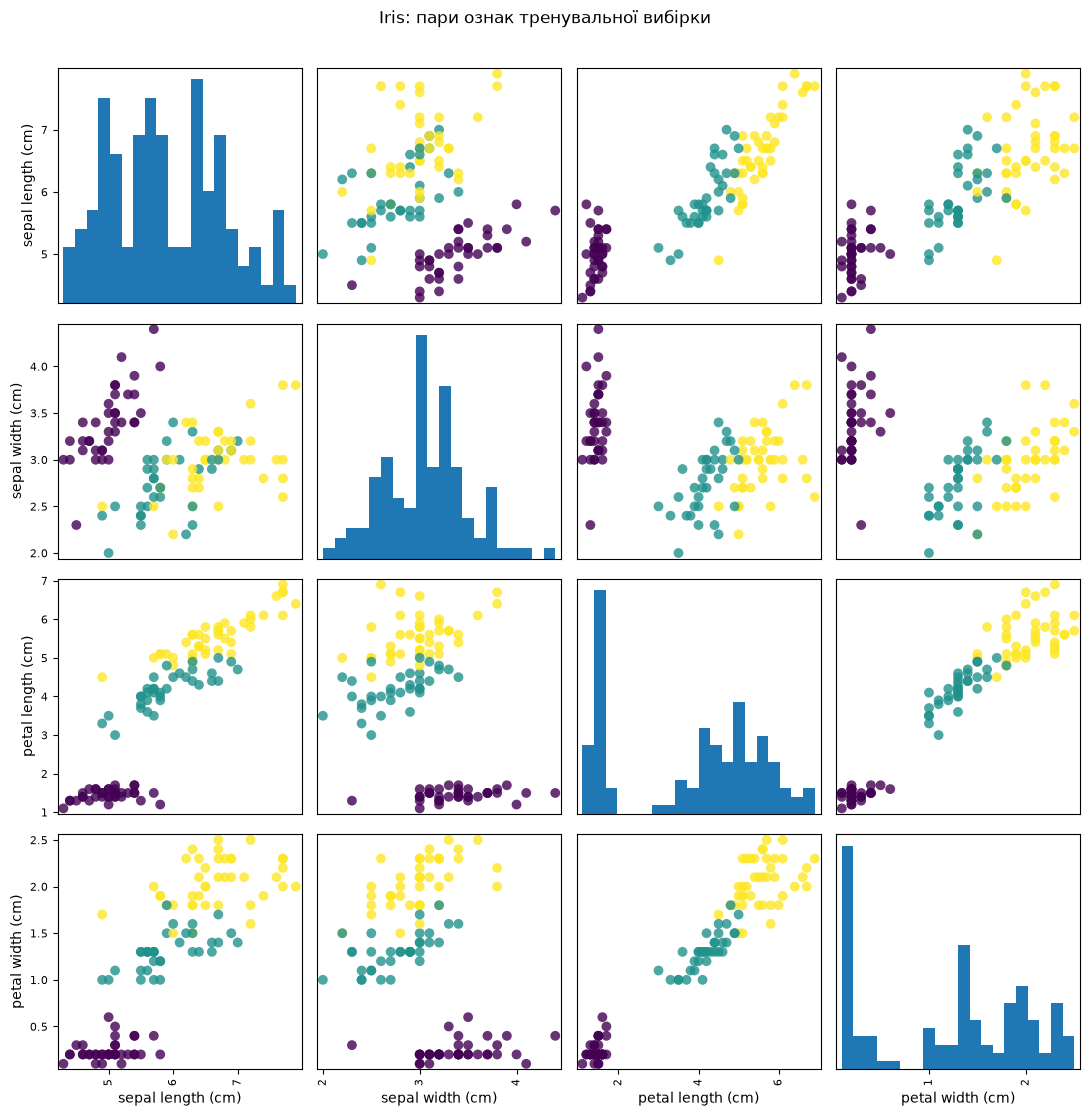

In [4]:
iris_dataframe = pd.DataFrame(X_train, columns=iris_dataset.feature_names)
axes = scatter_matrix(
    iris_dataframe,
    c=y_train,
    figsize=(11, 11),
    marker="o",
    hist_kwds={"bins": 20},
    s=50,
    alpha=0.8,
    cmap=plt.cm.viridis,
)
plt.suptitle("Iris: пари ознак тренувальної вибірки", y=1.01)
plt.tight_layout()
plt.show()


## 4. Навчання моделі k найближчих сусідів

Як у книзі, беремо одного найближчого сусіда (`k=1`). Метод `fit` навчає класифікатор на тренувальній вибірці.


In [5]:
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train, y_train)
print("Модель навчено; k =", knn.n_neighbors)


Модель навчено; k = 1


## 5. Передбачення для нової квітки

Виміри в порядку ознак набору: довжина чашолистка, ширина чашолистка, довжина пелюстки, ширина пелюстки. Навіть один зразок має бути двовимірним масивом форми `(1, 4)`.


In [6]:
X_new = np.array([[5.0, 2.9, 1.0, 0.2]])
prediction = knn.predict(X_new)
print("Форма нового зразка:", X_new.shape)
print("Код класу:", prediction[0])
print("Передбачений вид:", iris_dataset.target_names[prediction[0]])


Форма нового зразка: (1, 4)
Код класу: 0
Передбачений вид: setosa


## 6. Перевірка якості

Порівнюємо передбачення з відомими мітками відкладеної тестової вибірки. Точність — частка правильних відповідей.


In [7]:
y_pred = knn.predict(X_test)
accuracy = np.mean(y_pred == y_test)
print("Передбачення для тестових даних:\n", y_pred)
print(f"Правильних передбачень: {np.sum(y_pred == y_test)} із {len(y_test)}")
print(f"Точність (np.mean): {accuracy:.4f}")
print(f"Точність (knn.score): {knn.score(X_test, y_test):.4f}")


Передбачення для тестових даних:
 [2 1 0 2 0 2 0 1 1 1 2 1 1 1 1 0 1 1 0 0 2 1 0 0 2 0 0 1 1 0 2 1 0 2 2 1 0
 2]
Правильних передбачень: 37 із 38
Точність (np.mean): 0.9737
Точність (knn.score): 0.9737


## Висновок

Модель `KNeighborsClassifier` з одним сусідом правильно визначає 37 із 38 квіток тестової вибірки — приблизно **97%**. Новий зразок `[5, 2.9, 1, 0.2]` класифіковано як **setosa**. Оцінка отримана на даних, які модель не бачила під час навчання.
